# Flood Susceptibility Mapping: Watershed-Scale Approach

The following instructions outline the process of calculating flood susceptibility at the watershed scale using the Weight of Evidence (WoE) and Analytic Hierarchy Process (AHP) methods. The methodology integrates multiple environmental conditioning factors according to data availability and the characteristics of the study area. 

In this case, geomorphology, land cover, slope, and distance to water bodies are analyzed in relation to the historical flood inventory of the San Jorge River basin, located in northern Colombia.

## Historical flood events

Historical flood events reflects the occurrence of past floods through historical records, official reports, in situ observations, or remote sensing data. These resources provide information on the location, timing, and extent of flooding. The recorded information can be compiled into a flood inventory to support flood susceptibility modeling and model validatation (Huang et al., 2021; Multisourced Flood Inventories over the Contiguous United States for Actual and Natural Conditions, 2021).


### Preparing the watershed mask

The watershed mask defines the spatial extent of the study area and identifies the raster cells included in the analysis. In this workflow, cells inside the San Jorge River basin are represented by 1, whereas cells outside the basin are represented by 0. Cells outside the study area are subsequently excluded from the flood-susceptibility calculations using a Boolean mask.

In [5]:
import rasterio as rio
import numpy as np
from rasterio.plot import show
import matplotlib.pyplot as plt
import pandas as pd

In [6]:
# Open the mask raster with its metadata
with rio.open(r"D:\CVS_RONDA_HIDRICA\WoE\CuencaSanJorge\Mask\Mask.tif") as src:
    mask = src.read(1).astype("float32")
    profile = src.profile
    nodata = src.nodata if src.nodata is not None else -999

# Inspect the pixel values
values, counts = np.unique(mask, return_counts = True)
print(pd.DataFrame({  "Value": values,  "Pixel_count": counts}))

# Modify NoData mask values to NaN
mask[mask == nodata] = np.nan

   Value  Pixel_count
0    0.0     54719021
1    1.0     39168718


In [7]:
# Total valid basin pixels (where mask == 1)
total_basin_cells = np.sum(mask == 1)

### Importing historical flood events

The historical flood inventory is loaded as a raster representing the spatial distribution of documented flood occurrences across the study area. Before proceeding, ensure that the flood inventory and watershed mask have the same dimensions and are spatially aligned.

Flood inventory cells classified as flooded are assigned a value of 1, while non-flooded cells and cells outside the watershed are assigned a value of 0. This binary representation supports the subsequent calculation of Weight of Evidence (WoE) values for each conditioning-factor class.

In [8]:
# Identify the cells in mask that are not NaN
inside = ~np.isnan(mask)

# Read the flood inventory and identify the raster's NoData value (use NoData value or assume -999)
with rio.open(r'D:\CVS_RONDA_HIDRICA\WoE\CuencaSanJorge\Inundacion\InuN_SanJorge.tif') as src:
    inventario = src.read(1)
    flood_nodata = src.nodata if src.nodata is not None else -999

# Chech the raster have the same rows and columns
assert inventario.shape == mask.shape, "Inventory and mask have different dimensions"

# Convert flood NoData and outside areas to 0
inventario = np.where(inventario == flood_nodata, 0, inventario)
inventario = np.where(inside, inventario, 0).astype("uint8")

# Count flood pixels
total_flood_cells = (inventario == 1).sum()
print(f"Total basin cells: {total_basin_cells}")
print(f"Total flooded cells: {total_flood_cells}")

Total basin cells: 39168718
Total flooded cells: 1718008


## Weight of Evidence (WoE)

Weights of Evidence is a data-driven, bivariate statistical modeling technique used for spatial prediction and susceptibility assessment, such as mapping areas susceptible to floods. Rather than relying on subjective expert opinions (knowledge-driven modeling), the method determines weights objectively by calculating probability densities based on historical and present occurrences.

<div  style="text-align: center;">
  <img src="https://raw.githubusercontent.com/rjpachecov/images/bb2948168cf3407dbbe7b749fa4ccd16085fd8cf/woe_grid_flood_B.jpg" width="700">   
  <p style="text-align: center;"><em>Figure: Spatial raster representation showing the relationship between Subclass B and event presence/absence for calculating $\text{Npix}_1$ through $\text{Npix}_4$.</em></p>
</div>

In this workflow, probability densities are estimated from the historical flood inventory to quantify the spatial association between flood occurrence and the subclasses of each conditioning factor. For instance, a particular subclass B may contain both flooded pixels $\text{Npix}_1$ and non-flooded pixels $\text{Npix}_3$. Similarly, pixels outside subclass B may include flooded pixels $\text{Npix}_2$ and non-flooded pixels $\text{Npix}_2$.

| | | Subclass Status | |
| :---: | :---: | :---: | :---: |
| | | Belongs | Does not belong |
| **Flooding** | Presence | True positive<br>$\text{Npix}_1$ | False positive<br>$\text{Npix}_2$ |
| | Absence | False negative<br>$\text{Npix}_3$ | True negative<br>$\text{Npix}_4$ |

The Weight of Evidence can be written in numbers of pixels as follows:

$$
W_{i}^{+} = \log_{e} \dfrac{\dfrac{\text{Npix}_{1}}{\text{Npix}_{1} + \text{Npix}_{2}}}{\dfrac{\text{Npix}_{3}}{\text{Npix}_{3} + \text{Npix}_{4}}} \quad \text{;} \quad W_{i}^{-} = \log_{e} \dfrac{\dfrac{\text{Npix}_{2}}{\text{Npix}_{1} + \text{Npix}_{2}}}{\dfrac{\text{Npix}_{4}}{\text{Npix}_{3} + \text{Npix}_{4}}}
$$

### Contrast Factor ($C_W$)
To quantify the spatial association between a map class and the occurrence of flood, the contrast factor is defined as the difference between positive and negative weights:

$$C_W = W^+ - W^-$$

* **$C_W = 0$:** The flood pattern and map class overlap only by chance.
* **$C_W > 0$:** Positive association; the class favors flood occurrence.
* **$C_W < 0$:** Negative association; the class is unfavorable for flooding.

### Final Weights for Multi-Class Maps ($W_{map}$)

Because conditioning factor maps (such as geomorphology or land cover) contain multiple classes, the presence of one specific class implicitly means the absence of the other classes within that same map. To account for this, the final total weight for a given class is calculated by combining its positive weight with the sum of the negative weights of all other classes in that map:

$$W_{map} = W^+ + W_{mintotal} - W^-$$

where:
* $W^+$ = Positive weight of the specific class.
* $W^-$ = Negative weight of the specific class.
* $W_{mintotal}$ = Total sum of all negative weights across all classes within that multi-class map.

## Conditioning factors

### Geomorphology

The geomorphological map is processed as a multi-class conditioning factor. Using the historical flood inventory and the watershed mask, pixel counts ($\text{Npix}_1$ through $\text{Npix}_4$) are computed for each geomorphological unit to derive positive weights ($W^+$), negative weights ($W^-$), contrast factors ($C_W$), and final multi-class weights ($W_{map}$).

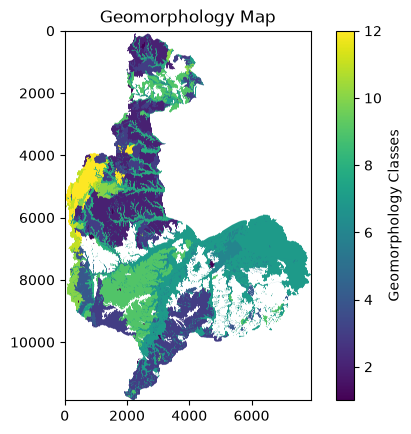

Detected geomorphology classes (12): [ 1  2  3  4  5  6  7  8  9 10 11 12]


In [9]:
# Load and process geomorphology
geomorphology = r'D:\CVS_RONDA_HIDRICA\WoE\CuencaSanJorge\Raster_Geomorfologia\Raster_Geomorfologia.tif'
with rio.open(geomorphology) as src:
    geomorphology = src.read(1).astype("float32")
    geo_nodata = src.nodata if src.nodata is not None else -999

assert geomorphology.shape == inside.shape, "Geomorphology and mask have different dimensions"

# Convert geomorphology NoData and outside areas to NaN
geomorphology[geomorphology == geo_nodata] = np.nan
geomorphology[~inside] = np.nan

# Check the raster
plt.imshow(geomorphology, cmap = "viridis")
plt.colorbar(label = "Geomorphology Classes")
plt.title("Geomorphology Map")
plt.show()

# Find all unique classes present in the raster (excluding 0/background)
unique_classes = np.unique(geomorphology[geomorphology > 0]).astype(int)
print(f"Detected geomorphology classes ({len(unique_classes)}): {unique_classes}")

Classes: {1: 'Ar', 2: 'Dld', 3: 'Dlo', 4: 'FAa', 5: 'Fa', 6: 'Fca', 7: 'Fpi', 8: 'Ftaa', 9: 'Ftab', 10: 'Scor', 11: 'Slcp', 12: 'Sle'}

In [10]:
data_records = []

for cls in unique_classes:
    total_cells = np.sum(geomorphology == cls)
    flooded_cells = np.sum((geomorphology == cls) & (inventario == 1))
    
    data_records.append({
        'Clase': cls,
        'Celdas_Totales': total_cells,
        'Celdas_Inundadas': flooded_cells
    })

# Convert records into a clean Pandas DataFrame
df = pd.DataFrame(data_records).set_index('Clase')

In [13]:
# Contingency table components (x1, x2, x3, x4)
df['x1'] = df['Celdas_Inundadas']
df['x2'] = total_flood_cells - df['Celdas_Inundadas']
df['x3'] = df['Celdas_Totales'] - df['Celdas_Inundadas']
df['x4'] = (total_basin_cells - df['Celdas_Totales']) - df['x2']

# Weights calculation
df['Wp'] = np.log((df['x1'] / (df['x1'] + df['x2'])) / (df['x3'] / (df['x3'] + df['x4'])))
df['Wn'] = np.log((df['x2'] / (df['x1'] + df['x2'])) / (df['x4'] / (df['x3'] + df['x4'])))

# Contrast
df['Contrast'] = df['Wp'] - df['Wn']

# Final Multi-Class Weight (W_map) calculation
w_mintotal = df['Wn'].sum()
df['W_map'] = df['Wp'] + w_mintotal - df['Wn']

# Preview final table
print("\n--- WoE Results Preview ---")
print(df.head())


--- WoE Results Preview ---
       Celdas_Totales  Celdas_Inundadas    x1       x2       x3        x4  \
Clase                                                                       
1              110576                 0     0  1718008   110576  37340134   
2             4990361               562   562  1717446  4989799  32460911   
3             6168826              7895  7895  1710113  6160931  31289779   
4              811718              8460  8460  1709548   803258  36647452   
5              641532              8237  8237  1709771   633295  36817415   

             Wp        Wn  Contrast     W_map  
Clase                                          
1          -inf  0.002957      -inf      -inf  
2     -6.009544  0.142662 -6.152206 -6.604891  
3     -3.577893  0.175128 -3.753021 -4.205706  
4     -1.471467  0.016745 -1.488212 -1.940897  
5     -1.260440  0.012249 -1.272689 -1.725374  


C:\Users\User\miniconda3\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [15]:
# Replace any infinite values with NaN
df.replace([np.inf, -np.inf], np.nan, inplace = True)

# Find the minimum valid contrast value from the other classes
min_contrast = df['Contrast'].min()
print(f"Minimum contrast value found: {min_contrast}")

# Assign that minimum value to the classes that had NaN / zero floods
# Target only the columns where you want to replace NaN with the minimum contrast
cols_to_fix = ['Contrast', 'Wp', 'Wn']
for col in cols_to_fix:
    if col in df.columns:
        df[col] = df[col].fillna(min_contrast)

# Recalculate W_map using the updated Wp and Wn values
w_mintotal = df['Wn'].sum()
df['W_map'] = df['Wp'] + w_mintotal - df['Wn']

# Export Excel
df.to_excel(r'D:\CVS_RONDA_HIDRICA\WoE\CuencaSanJorge\Raster_Geomorfologia\PesosGeomorfologia.xlsx')

Minimum contrast value found: -6.152206013029883


In [19]:
# Create a lookup dictionary from our dataframe
w_map_dict = dict(zip(df.index, df['W_map']))

# Initialize the output array with NaNs
geomorphology_w = np.full_like(geomorphology, np.nan, dtype = np.float32)

# Map the calculated W Map values from the dictionary to the raster
for class_id, w_map_val in w_map_dict.items():
    geomorphology_w[geomorphology == class_id] = w_map_val

# If any valid pixels inside your study area ('inside') missed a class match, 
# or if you want them explicitly forced to the minimum contrast value:
min_w_map = df['W_map'].min()
geomorphology_w[np.isnan(geomorphology_w) & inside] = min_w_map

In [20]:
# Print unique values and pixel counts for validation
valid_pixels = geomorphology_w[~np.isnan(geomorphology_w)]
unique_vals, counts = np.unique(valid_pixels, return_counts = True)
print("W Map values and pixel counts:")
print(np.asarray((unique_vals, counts)).T)

W Map values and pixel counts:
[[-6.63430643e+00  8.81175100e+06]
 [-6.60784769e+00  1.10576000e+05]
 [-6.60489082e+00  4.99036100e+06]
 [-4.20570660e+00  6.16882600e+06]
 [-3.74846482e+00  2.28501900e+06]
 [-2.97409272e+00  8.38124000e+05]
 [-1.99608099e+00  4.14958000e+06]
 [-1.99582374e+00  4.23732000e+05]
 [-1.94089687e+00  8.11718000e+05]
 [-1.72537363e+00  6.41532000e+05]
 [ 8.22014287e-02  8.84789200e+06]
 [ 5.87889433e+00  1.08960700e+06]]


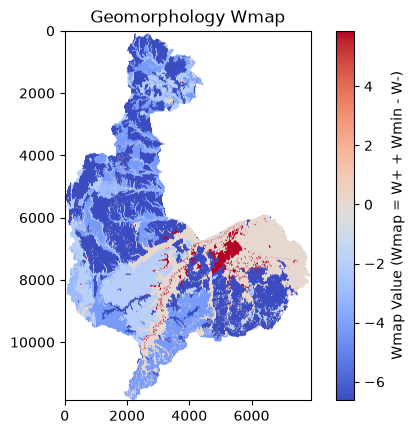

In [21]:
# Check the contrast map
plt.imshow(geomorphology_w, cmap = "coolwarm")
plt.colorbar(label = "Wmap Value (Wmap = W+ + Wmin - W-)")
plt.title("Geomorphology Wmap")
plt.show()

In [23]:
# Save the raster output
output_raster_data = np.where(np.isnan(geomorphology_w), -999, geomorphology_w)
profile.update(dtype = "float32", nodata = -999, compress = "lzw")

with rio.open(r'D:\CVS_RONDA_HIDRICA\WoE\CuencaSanJorge\Raster_Geomorfologia\Geomorfologia_Wmap.tif', "w", **profile) as dst:
    dst.write(output_raster_data, 1)

### Water body distance

The distance to water bodies is evaluated as a multi-class conditioning factor divided into specific distance intervals or buffer zones. Because each pixel falls into one mutually exclusive distance class, we apply the Weights of Evidence methodology using contingency table statistics ($\text{Npix}_1$–$\text{Npix}_4$) to calculate positive weights, negative weights, contrast factors, and final multi-class weights ($W_{map}$).

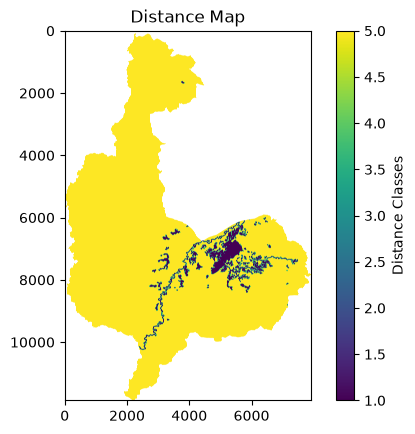

Detected distance classes (5): [1 2 3 4 5]


In [44]:
# Load and process water body distance
distance = r'D:\CVS_RONDA_HIDRICA\WoE\CuencaSanJorge\Raster_Distancia\Raster_Distancia.tif'
with rio.open(distance) as src:
    distance = src.read(1).astype("float32")
    geo_nodata = src.nodata if src.nodata is not None else -999

assert distance.shape == inside.shape, "Distance and mask have different dimensions"

# Convert distance NoData and outside areas to NaN
distance[distance == geo_nodata] = np.nan
distance[~inside] = np.nan

# Check the raster
plt.imshow(distance, cmap="viridis")
plt.colorbar(label="Distance Classes")
plt.title("Distance Map")
plt.show()

# Find all unique classes present in the raster (excluding 0/background)
unique_classes = np.unique(distance[distance > 0]).astype(int)
print(f"Detected distance classes ({len(unique_classes)}): {unique_classes}")

Classes: {1: '0 - 30 m', 2: '30 - 60 m', 3: '60 - 120 m', 4: '120 - 240 m', 5: '> 240 m'}

In [45]:
data_records = []

for cls in unique_classes:
    total_cells = np.sum(distance == cls)
    flooded_cells = np.sum((distance == cls) & (inventario == 1))
    
    data_records.append({
        'Clase': cls,
        'Celdas_Totales': total_cells,
        'Celdas_Inundadas': flooded_cells
    })

# Convert records into a clean Pandas DataFrame
df = pd.DataFrame(data_records).set_index('Clase')

In [46]:
# Contingency table components (x1, x2, x3, x4)
df['x1'] = df['Celdas_Inundadas']
df['x2'] = total_flood_cells - df['Celdas_Inundadas']
df['x3'] = df['Celdas_Totales'] - df['Celdas_Inundadas']
df['x4'] = (total_basin_cells - df['Celdas_Totales']) - df['x2']

# Weights calculation
df['Wp'] = np.log((df['x1'] / (df['x1'] + df['x2'])) / (df['x3'] / (df['x3'] + df['x4'])))
df['Wn'] = np.log((df['x2'] / (df['x1'] + df['x2'])) / (df['x4'] / (df['x3'] + df['x4'])))

# Contrast
df['Contrast'] = df['Wp'] - df['Wn']

# Preview final table
print("\n--- WoE Results Preview ---")
print(df.head())


--- WoE Results Preview ---
       Celdas_Totales  Celdas_Inundadas       x1       x2        x3        x4  \
Clase                                                                           
1             1254022           1005882  1005882   712126    248140  37202570   
2              247459             11069    11069  1706939    236390  37214320   
3              443248             24369    24369  1693639    418879  37031831   
4              750687             52635    52635  1665373    698052  36752658   
5            36473302            624053   624053  1093955  35849249   1601461   

             Wp        Wn  Contrast  
Clase                                
1      4.481487 -0.874018  5.355505  
2      0.020526 -0.000132  0.020657  
3      0.237590 -0.003038  0.240628  
4      0.496948 -0.012301  0.509249  
5     -0.968982  2.700743 -3.669726  


In [47]:
# Replace infinite values with NaN, then fill NaN with 0
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.fillna(0, inplace=True)

# Export Excel
df.to_excel(r'D:\CVS_RONDA_HIDRICA\WoE\CuencaSanJorge\Raster_Distancia\PesosDistancia.xlsx')

In [48]:
# Create a lookup dictionary from our dataframe
contrast_dict = dict(zip(df.index, df['Contrast']))

# Initialize the output array with NaNs
distance_c = np.full_like(distance, np.nan, dtype = np.float32)

# Map the calculated contrast values from the dictionary to the raster
for class_id, contrast_val in contrast_dict.items():
    distance_c[distance == class_id] = contrast_val

In [49]:
# Print unique values and pixel counts for validation
valid_pixels = distance_c[~np.isnan(distance_c)]
unique_vals, counts = np.unique(valid_pixels, return_counts = True)
print("Contrast values and pixel counts:")
print(np.asarray((unique_vals, counts)).T)

Contrast values and pixel counts:
[[-3.66972589e+00  3.64733020e+07]
 [ 2.06573512e-02  2.47459000e+05]
 [ 2.40628108e-01  4.43248000e+05]
 [ 5.09249151e-01  7.50687000e+05]
 [ 5.35550499e+00  1.25402200e+06]]


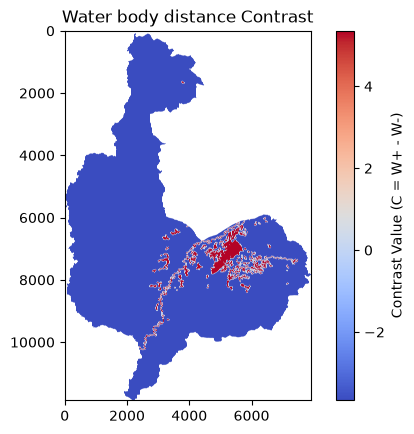

In [50]:
# Check the contrast map
plt.imshow(distance_c, cmap = "coolwarm")
plt.colorbar(label = "Contrast Value (C = W+ - W-)")
plt.title("Water body distance Contrast")
plt.show()

In [21]:
# Save the raster output
output_raster_data = np.where(np.isnan(distance_c), -999, distance_c)
profile.update(dtype = "float32", nodata = -999, compress = "lzw")

with rio.open(r'D:\CVS_RONDA_HIDRICA\WoE\CuencaSanJorge\Raster_Distancia\Distancia_Contraste.tif', "w", **profile) as dst:
    dst.write(output_raster_data, 1)

### Land cover

Land cover acts as a multi-class conditioning factor representing surface characteristics and vegetation types. Each pixel belongs to a specific land use/cover category. Using the historical flood inventory, we extract the contingency table components ($\text{Npix}_1$–$\text{Npix}_4$) for each land cover class to calculate positive weights, negative weights, contrast factors, and the final multi-class weights ($W_{map}$).

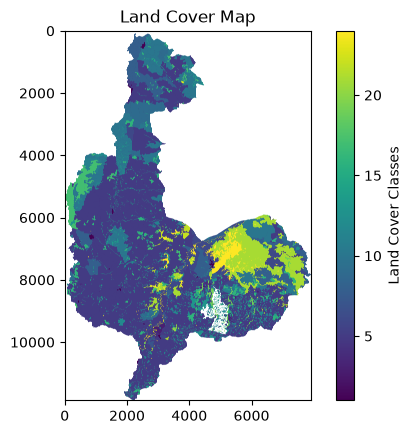

Detected landcover classes (24): [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24]


In [34]:
# Load and process land cover
landcover = r'D:\CVS_RONDA_HIDRICA\WoE\CuencaSanJorge\Raster_Cobertura\Raster_Cobertura.tif'
with rio.open(landcover) as src:
    landcover = src.read(1).astype("float32")
    geo_nodata = src.nodata if src.nodata is not None else -999

assert landcover.shape == inside.shape, "Land Cover and mask have different dimensions"

# Convert landcover NoData and outside areas to NaN
landcover[landcover == geo_nodata] = np.nan
landcover[~inside] = np.nan

# Check the raster
plt.imshow(landcover, cmap = "viridis")
plt.colorbar(label = "Land Cover Classes")
plt.title("Land Cover Map")
plt.show()

# Find all unique classes present in the raster (excluding 0/background)
unique_classes = np.unique(landcover[landcover > 0]).astype(int)
print(f"Detected landcover classes ({len(unique_classes)}): {unique_classes}")

Classes: {1: 111.0, 2: 122.0, 3: 211.0, 4: 231.0, 5: 232.0, 6: 233.0, 7: 241.0, 8: 242.0, 9: 243.0, 10: 244.0, 11: 311.0, 12: 312.0, 13: 313.0, 14: 314.0, 15: 315.0, 16: 322.0, 17: 323.0, 18: 331.0, 19: 333.0, 20: 334.0, 21: 411.0, 22: 413.0, 23: 511.0, 24: 512.0}

In [35]:
data_records = []

for cls in unique_classes:
    total_cells = np.sum(landcover == cls)
    flooded_cells = np.sum((landcover == cls) & (inventario == 1))
    
    data_records.append({
        'Clase': cls,
        'Celdas_Totales': total_cells,
        'Celdas_Inundadas': flooded_cells
    })

# Convert records into a clean Pandas DataFrame
df = pd.DataFrame(data_records).set_index('Clase')

In [36]:
# Contingency table components (x1, x2, x3, x4)
df['x1'] = df['Celdas_Inundadas']
df['x2'] = total_flood_cells - df['Celdas_Inundadas']
df['x3'] = df['Celdas_Totales'] - df['Celdas_Inundadas']
df['x4'] = (total_basin_cells - df['Celdas_Totales']) - df['x2']

# Weights calculation
df['Wp'] = np.log((df['x1'] / (df['x1'] + df['x2'])) / (df['x3'] / (df['x3'] + df['x4'])))
df['Wn'] = np.log((df['x2'] / (df['x1'] + df['x2'])) / (df['x4'] / (df['x3'] + df['x4'])))

# Contrast
df['Contrast'] = df['Wp'] - df['Wn']

# Preview final table
print("\n--- WoE Results Preview ---")
print(df.head())


--- WoE Results Preview ---
       Celdas_Totales  Celdas_Inundadas      x1       x2        x3        x4  \
Clase                                                                          
1               98940                85      85  1717923     98855  37351855   
2              114459               701     701  1717307    113758  37336952   
3              106832             25507   25507  1692501     81325  37369385   
4               54532             10542   10542  1707466     43990  37406720   
5            20751098            397938  397938  1320070  20353160  17097550   

             Wp        Wn  Contrast  
Clase                                
1     -3.976898  0.002594 -3.979492  
2     -2.007461  0.002634 -2.010095  
3      1.922360 -0.012784  1.935144  
4      1.653265 -0.004980  1.658245  
5     -0.852835  0.520610 -1.373445  


C:\Users\User\miniconda3\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [37]:
# Replace any infinite values with NaN
df.replace([np.inf, -np.inf], np.nan, inplace = True)

# Find the minimum valid contrast value from the other classes
min_contrast = df['Contrast'].min()
print(f"Minimum contrast value found: {min_contrast}")

# Assign that minimum value to the classes that had NaN / zero floods
# Target only the columns where you want to replace NaN with the minimum contrast
cols_to_fix = ['Contrast', 'Wp', 'Wn']
for col in cols_to_fix:
    if col in df.columns:
        df[col] = df[col].fillna(min_contrast)

# Export Excel
df.to_excel(r'D:\CVS_RONDA_HIDRICA\WoE\CuencaSanJorge\Raster_Cobertura\PesosCobertura.xlsx')

Minimum contrast value found: -4.316179699847324


In [38]:
# Create a lookup dictionary from our dataframe
contrast_dict = dict(zip(df.index, df['Contrast']))

# Initialize the output array with NaNs
landcover_c = np.full_like(landcover, np.nan, dtype = np.float32)

# Map the calculated contrast values from the dictionary to the raster
for class_id, contrast_val in contrast_dict.items():
    landcover_c[landcover == class_id] = contrast_val

# If any valid pixels inside your study area ('inside') missed a class match, 
# or if you want them explicitly forced to the minimum contrast value:
min_contrast = df['Contrast'].min()
landcover_c[np.isnan(landcover_c) & inside] = min_contrast

In [39]:
# Print unique values and pixel counts for validation
valid_pixels = landcover_c[~np.isnan(landcover_c)]
unique_vals, counts = np.unique(valid_pixels, return_counts = True)
print("Contrast values and pixel counts:")
print(np.asarray((unique_vals, counts)).T)

Contrast values and pixel counts:
[[-4.31617975e+00  7.28301000e+05]
 [-4.17677021e+00  9.83084000e+05]
 [-3.97949147e+00  9.89400000e+04]
 [-2.65385270e+00  8.69044000e+05]
 [-2.36439490e+00  9.06962000e+05]
 [-2.25551128e+00  9.98504000e+05]
 [-2.11615896e+00  4.21895800e+06]
 [-2.01009464e+00  1.14459000e+05]
 [-1.99180627e+00  6.28759000e+05]
 [-1.37344480e+00  2.07510980e+07]
 [-1.24768591e+00  1.94875000e+05]
 [-1.01820004e+00  4.69782000e+05]
 [-7.31451273e-01  2.51733500e+06]
 [ 8.03911388e-01  1.51804200e+06]
 [ 1.14657640e+00  2.86551300e+06]
 [ 1.42632866e+00  1.58383000e+05]
 [ 1.65824497e+00  5.45320000e+04]
 [ 1.93514395e+00  1.06832000e+05]
 [ 1.99856925e+00  1.46987000e+05]
 [ 2.64888597e+00  5.22700000e+03]
 [ 3.87321329e+00  9.44160000e+04]
 [ 4.87517977e+00  7.38685000e+05]]


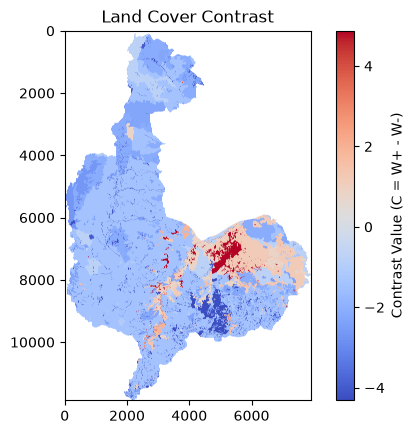

In [40]:
# Check the contrast map
plt.imshow(landcover_c, cmap = "coolwarm")
plt.colorbar(label = "Contrast Value (C = W+ - W-)")
plt.title("Land Cover Contrast")
plt.show()

In [42]:
# Save the raster output
output_raster_data = np.where(np.isnan(landcover_c), -999, landcover_c)
profile.update(dtype = "float32", nodata = -999, compress = "lzw")

with rio.open(r'D:\CVS_RONDA_HIDRICA\WoE\CuencaSanJorge\Raster_Cobertura\Cobertura_Contraste.tif', "w", **profile) as dst:
    dst.write(output_raster_data, 1)

### Slope

Slope gradient is a key conditioning factor controlling runoff velocity and susceptibility to flooding. Classified into categorical percentage intervals following standard guidelines (IGAC, 2013 & MADS, 2014), each pixel falls into one mutually exclusive slope class. Using the historical flood inventory, we extract the contingency table components ($\text{Npix}_1$–$\text{Npix}_4$) for each slope interval to compute positive weights, negative weights, contrast factors, and final multi-class weights ($W_{map}$).

_**Table 1**. Classification of slope ranges (IGAC, 2013 & MADS, 2014)._

| Slope, in percentage | Classification |
|:--------:|:-------------------------|
| 0 - 3    | Flat                |
| 3 - 7    | Slightly inclined   |
| 7 - 12   | Moderately inclined | 
| 12 - 25  | Strongly inclined | 
| 25 - 50  | Slightly steep | 
| 50 - 75  | Moderately steep |
| > 75  | Strongly steep | 


In [51]:
# Load and process slope
slope = r'D:\CVS_RONDA_HIDRICA\WoE\CuencaSanJorge\Raster_Pendiente\Raster_Pendiente.tif'

with rio.open(slope) as src:
    slope = src.read(1).astype("float32")
    geo_nodata = src.nodata if src.nodata is not None else -999

# Check dimensions against our study area mask
assert slope.shape == inside.shape, "Slope and mask have different dimensions"

# Convert slope NoData and outside areas to NaN
slope[slope == geo_nodata] = np.nan
slope[~inside] = np.nan

In [52]:
# Reclassify slope values into percentage classes
classes = [
    (slope >= 0) & (slope <= 3),     # 0 - 3%: Flat
    (slope > 3) & (slope <= 7),      # 3 - 7%: Slightly inclined
    (slope > 7) & (slope <= 12),     # 7 - 12%: Moderately inclined
    (slope > 12) & (slope <= 25),    # 12 - 25%: Strongly inclined
    (slope > 25) & (slope <= 50),    # 25 - 50%: Slightly steep
    (slope > 50) & (slope <= 75),    # 50 - 75%: Moderately steep
    (slope > 75)                     # > 75%: Strongly steep
]

values = [1, 2, 3, 4, 5, 6, 7]

# Apply classification (unmatched or NaN pixels will remain NaN)
slope_classified = np.select(classes, values, default = np.nan)

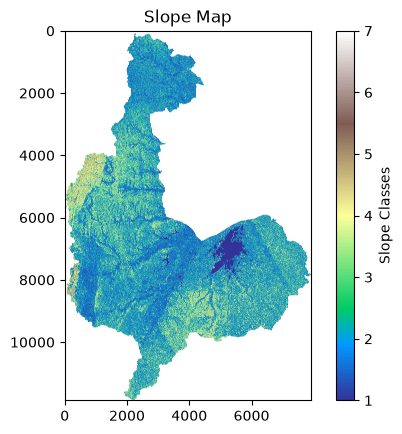

Detected slope classes (7): [1 2 3 4 5 6 7]


In [53]:
# Check the raster
plt.imshow(slope_classified, cmap = "terrain")
plt.colorbar(label = "Slope Classes")
plt.title("Slope Map")
plt.show()

# Find all unique classes present in the raster (excluding 0/background)
unique_classes = np.unique(slope_classified[slope_classified > 0]).astype(int)
print(f"Detected slope classes ({len(unique_classes)}): {unique_classes}")

Classes: {1: '0 - 3%', 2: '3 - 7%', 3: '7 - 12%', 4: '12 - 25%', 5: '25 - 50%', 6: '50 - 75%', 7: '> 75%'}

In [54]:
data_records = []

for cls in unique_classes:
    total_cells = np.sum(slope_classified == cls)
    flooded_cells = np.sum((slope_classified == cls) & (inventario == 1))
    
    data_records.append({
        'Clase': cls,
        'Celdas_Totales': total_cells,
        'Celdas_Inundadas': flooded_cells
    })

# Convert records into a clean Pandas DataFrame
df = pd.DataFrame(data_records).set_index('Clase')

In [55]:
# Contingency table components (x1, x2, x3, x4)
df['x1'] = df['Celdas_Inundadas']
df['x2'] = total_flood_cells - df['Celdas_Inundadas']
df['x3'] = df['Celdas_Totales'] - df['Celdas_Inundadas']
df['x4'] = (total_basin_cells - df['Celdas_Totales']) - df['x2']

# Weights calculation
df['Wp'] = np.log((df['x1'] / (df['x1'] + df['x2'])) / (df['x3'] / (df['x3'] + df['x4'])))
df['Wn'] = np.log((df['x2'] / (df['x1'] + df['x2'])) / (df['x4'] / (df['x3'] + df['x4'])))

# Contrast
df['Contrast'] = df['Wp'] - df['Wn']

# Preview final table
print("\n--- WoE Results Preview ---")
print(df.head())


--- WoE Results Preview ---
       Celdas_Totales  Celdas_Inundadas      x1       x2        x3        x4  \
Clase                                                                          
1             8601092            953594  953594   764414   7647498  29803212   
2            16339985            536710  536710  1181298  15803275  21647435   
3             9403978            169644  169644  1548364   9234334  28216376   
4             4285700             52005   52005  1666003   4233695  33217015   
5              473495              5411    5411  1712597    468084  36982626   

             Wp        Wn  Contrast  
Clase                                
1      0.999964 -0.581402  1.581366  
2     -0.300654  0.173587 -0.474241  
3     -0.915121  0.179157 -1.094278  
4     -1.317630  0.089225 -1.406856  
5     -1.378354  0.009423 -1.387777  


In [56]:
# Replace infinite values with NaN, then fill NaN with 0
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.fillna(0, inplace=True)

# Export Excel
df.to_excel(r'D:\CVS_RONDA_HIDRICA\WoE\CuencaSanJorge\Raster_Pendiente\PesosPendiente.xlsx')

In [57]:
# Create a lookup dictionary from our dataframe
contrast_dict = dict(zip(df.index, df['Contrast']))

# Initialize the output array with NaNs
slope_c = np.full_like(slope_classified, np.nan, dtype = np.float32)

# Map the calculated contrast values from the dictionary to the raster
for class_id, contrast_val in contrast_dict.items():
    slope_c[slope_classified == class_id] = contrast_val

In [37]:
# Print unique values and pixel counts for validation
valid_pixels = slope_c[~np.isnan(slope_c)]
unique_vals, counts = np.unique(valid_pixels, return_counts = True)
print("Contrast values and pixel counts:")
print(np.asarray((unique_vals, counts)).T)

Contrast values and pixel counts:
[[-1.40685570e+00  4.28570000e+06]
 [-1.38777649e+00  4.73495000e+05]
 [-1.16693866e+00  1.95950000e+04]
 [-1.09427798e+00  9.40397800e+06]
 [-6.88745141e-01  1.64300000e+03]
 [-4.74241436e-01  1.63399850e+07]
 [ 1.58136606e+00  8.60109200e+06]]


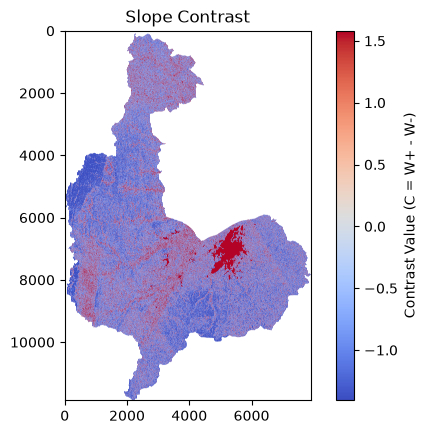

In [38]:
# Check the contrast map
plt.imshow(slope_c, cmap = "coolwarm")
plt.colorbar(label = "Contrast Value (C = W+ - W-)")
plt.title("Slope Contrast")
plt.show()

In [27]:
# Save the raster output
output_raster_data = np.where(np.isnan(slope_c), -999, slope_c)
profile.update(dtype = "float32", nodata = -999, compress = "lzw")

with rio.open(r'D:\CVS_RONDA_HIDRICA\WoE\CuencaSanJorge\Raster_Pendiente\Pendiente_Contraste.tif', "w", **profile) as dst:
    dst.write(output_raster_data, 1)

## Analytic Hierarchy Process (AHP)

To integrate the data-driven conditioning factors derived from Weights of Evidence, an **Analytic Hierarchy Process (AHP)** is applied to determine the relative importance weights of each factor map. Based on Saaty's pairwise comparison scale, factor weights are assigned as follows: Geomorphology ($G = 0.44$), Distance to water bodies ($D = 0.29$), Land cover ($L = 0.17$), and Slope ($S = 0.10$). 

The final **Flood Susceptibility Index (FSI)** is computed by combining the reclassified multi-class $W_{map}$ raster grids with their respective AHP factor weights:

$$\text{FSI} = (\text{Geomorphology}_{Wmap} \times G) + (\text{Distance}_{Wmap} \times D) + (\text{Landcover}_{Wmap} \times L) + (\text{Slope}_{Wmap} \times S)$$

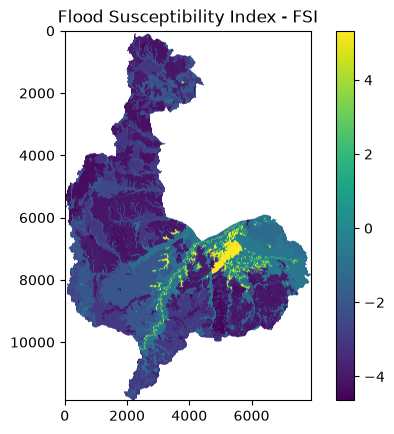

In [58]:
# Assign weights according to Satty's AHP
G = 0.44
D = 0.29
L = 0.17
S = 0.1

totalIS = G + D + L + S

# Calculate Flood Susceptibility Index (FSI)
FSI = geomorphology_c * G + distance_c * D + landcover_c * L + slope_c * S

# Create raster visualization
plt.imshow(FSI, cmap = "viridis")
plt.colorbar()
plt.title("Flood Susceptibility Index - FSI")
plt.show()

In [60]:
# Define an specific value that will act as NoData value in the output raster
nodata_value = -999

# Change the raster's pixel data type, assign NoData value and reduce the file size
output_raster_data = np.where(np.isnan(FSI), nodata_value, FSI)
profile.update(dtype = "float32", nodata = nodata_value, compress = "lzw")

# Export Flood Susceptibility Index (FSI)
with rio.open(r'D:\CVS_RONDA_HIDRICA\WoE\CuencaSanJorge\Raster_FSI\Flood_Susceptibility_Index.tif', "w", **profile) as dst:
    dst.write(output_raster_data, 1)